# Chapter 5 — Linear Models and Regularization
**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup  
**Environment:** Google Colab / Jupyter Notebook

## Learning objectives
- Fit and interpret an ordinary least-squares linear regression model.
- Compare Ridge, Lasso, and Elastic Net regression.
- Understand how regularization penalizes large coefficients and helps control overfitting.
- Use scaling, pipelines, and cross-validation to select regularization strength.
- Evaluate regression models with MSE, RMSE, and \(R^2\).

This notebook follows the chapter's recipe structure: **Introduction to linear models**, **Ridge and Lasso regression**, **ElasticNet and regularization**, **Regularization theory and practice**, and **Regression and regularization**. Examples use reproducible synthetic data so the experiments can be run without downloading external datasets.

## 1. Core ideas

A linear regression model predicts a continuous target using a weighted sum of features:

\[
\hat{y} = \beta_0 + \beta_1x_1 + \cdots + \beta_px_p
\]

Ordinary least squares (OLS) chooses coefficients that minimize the sum of squared residuals:

\[
\min_{\beta} \sum_{i=1}^{n}(y_i - \hat{y}_i)^2
\]

Regularization adds a penalty to discourage overly large coefficients:

- **Ridge (L2):** adds the sum of squared coefficients. It usually shrinks coefficients but rarely makes them exactly zero.
- **Lasso (L1):** adds the sum of absolute coefficients. It can set some coefficients exactly to zero, giving a sparse model.
- **Elastic Net:** combines L1 and L2 penalties, balancing sparsity and coefficient stability.

The parameter `alpha` controls penalty strength. A larger `alpha` means stronger regularization. Features should generally be scaled before comparing or penalizing coefficients, so the notebook uses `StandardScaler` inside pipelines. Keeping preprocessing inside the pipeline also prevents information from the test set leaking into training.

## 2. Setup and reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("NumPy:", np.__version__)

NumPy: 2.3.5


## 3. Introduction to linear models

Create a synthetic regression dataset with informative features and noise. The train/test split lets us evaluate predictions on observations that were not used to fit the model.

In [2]:
X, y = make_regression(
    n_samples=500,
    n_features=10,
    n_informative=6,
    noise=18.0,
    random_state=RANDOM_STATE
)
feature_names = [f"feature_{i+1}" for i in range(X.shape[1])]
X_df = pd.DataFrame(X, columns=feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X_df, y, test_size=0.25, random_state=RANDOM_STATE
)

print("Full dataset:", X_df.shape)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)
display(X_df.head())

Full dataset: (500, 10)
Training set: (375, 10) | Test set: (125, 10)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10
0,-0.739029,0.507020,1.427305,-0.707911,-0.419435,0.652330,-0.262747,-0.057395,-1.595894,-1.395449
1,0.838941,-0.320668,-0.558302,0.497743,-1.100154,-0.617253,0.665924,1.795211,0.421587,0.230071
2,0.711411,-2.099356,0.808036,0.566772,-0.848066,3.112910,-0.657373,0.683223,-0.048965,-0.114802
3,-0.072010,-0.479174,0.361636,-1.196207,-0.645120,1.003533,0.812526,-0.185659,1.356240,-1.106335
4,-0.772825,0.570891,-0.485364,0.651391,0.081874,-0.236819,-0.315269,1.135566,0.758969,0.954002


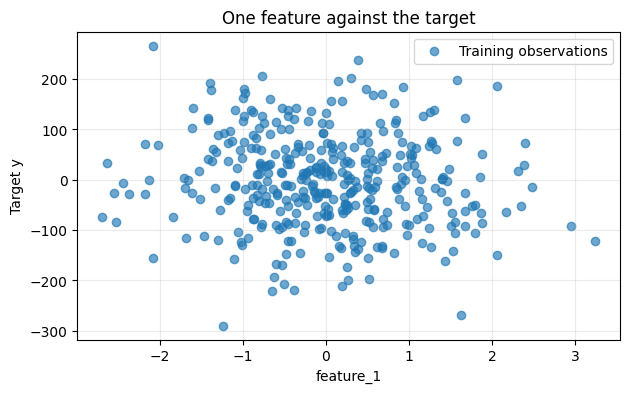

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(X_train["feature_1"], y_train, alpha=0.65, label="Training observations")
plt.xlabel("feature_1")
plt.ylabel("Target y")
plt.title("One feature against the target")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Fit an ordinary least-squares model

`LinearRegression` learns coefficients by minimizing squared prediction errors. The following helper evaluates any fitted regression estimator with MSE, RMSE, MAE, and \(R^2\).

In [4]:
def regression_metrics(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    mse = mean_squared_error(y_eval, predictions)
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_eval, predictions),
        "R2": r2_score(y_eval, predictions),
    }

ols = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
ols.fit(X_train, y_train)
ols_metrics = regression_metrics(ols, X_test, y_test)
print("OLS test metrics")
display(pd.DataFrame([ols_metrics], index=["LinearRegression"]).round(3))

OLS test metrics


,MSE,RMSE,MAE,R2
LinearRegression,316.508,17.791,13.865,0.97


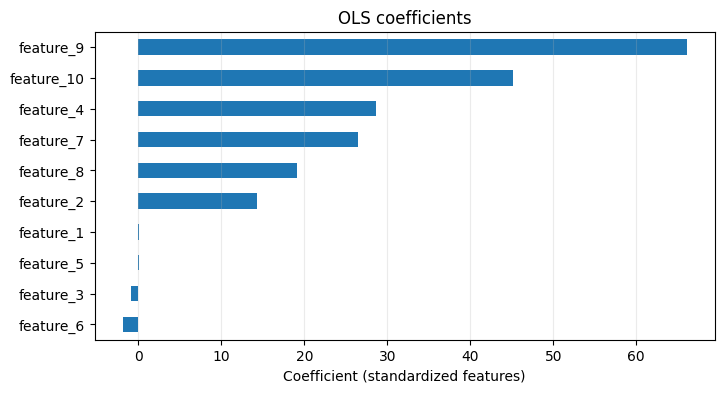

,coefficient
feature_9,66.055
feature_10,45.145
feature_4,28.673
feature_7,26.401
feature_8,19.089
feature_2,14.255
feature_6,-1.873
feature_3,-0.837
feature_1,0.125
feature_5,0.118


In [5]:
ols_coef = pd.Series(
    ols.named_steps["model"].coef_,
    index=feature_names
).sort_values(key=np.abs, ascending=False)

plt.figure(figsize=(8, 4))
ols_coef.sort_values().plot(kind="barh")
plt.xlabel("Coefficient (standardized features)")
plt.title("OLS coefficients")
plt.grid(axis="x", alpha=0.25)
plt.show()

display(ols_coef.rename("coefficient").to_frame().round(3))

**Interpretation:** coefficient signs indicate the direction of a feature's linear association with the prediction, holding other features fixed. Magnitudes are more comparable here because the input features were standardized. A coefficient by itself does not establish causation.

## 4. Ridge and Lasso regression

Ridge regression uses an L2 penalty; Lasso uses an L1 penalty. We compare them with OLS on the same held-out test set. Scaling is performed inside each pipeline, fitted only on the training split.

In [6]:
models = {
    "OLS": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge (alpha=10)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Lasso (alpha=1)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=1.0, max_iter=20000, random_state=RANDOM_STATE))
    ])
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({"Model": name, **regression_metrics(model, X_test, y_test)})

comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(3))

,MSE,RMSE,MAE,R2
Model,,,,
OLS,316.508,17.791,13.865,0.970
Ridge (alpha=10),342.292,18.501,14.521,0.967
Lasso (alpha=1),342.363,18.503,14.524,0.967


,OLS,Ridge (alpha=10),Lasso (alpha=1)
feature_1,0.125,-0.128,-0.000
feature_2,14.255,13.994,13.425
feature_3,-0.837,-0.745,-0.000
feature_4,28.673,27.765,27.342
feature_5,0.118,0.183,0.000
feature_6,-1.873,-1.692,-0.754
feature_7,26.401,25.749,25.412
feature_8,19.089,18.452,17.989
feature_9,66.055,64.222,64.861
feature_10,45.145,43.936,44.223


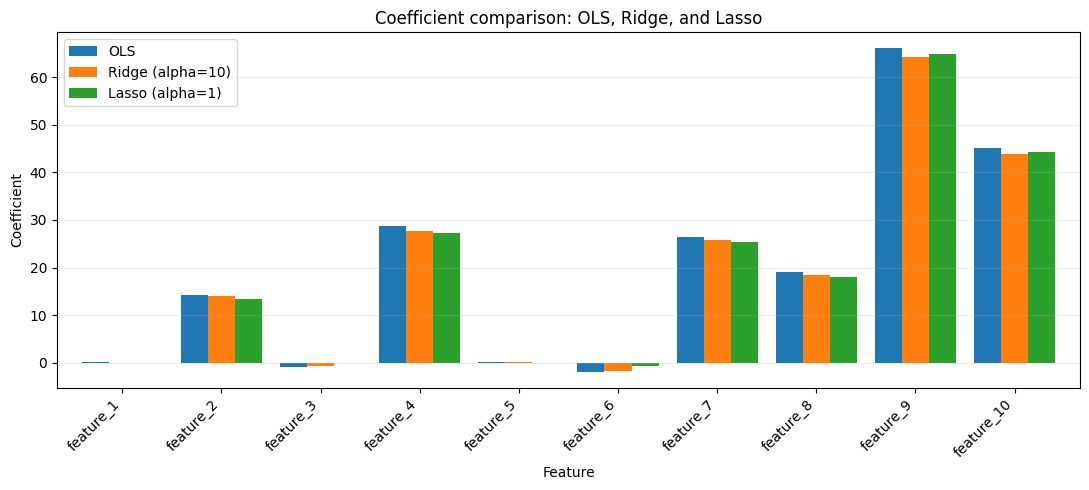

In [7]:
coef_table = pd.DataFrame(index=feature_names)
for name, model in models.items():
    coef_table[name] = model.named_steps["model"].coef_

display(coef_table.round(3))

ax = coef_table.plot(kind="bar", figsize=(11, 5), width=0.82)
ax.set_title("Coefficient comparison: OLS, Ridge, and Lasso")
ax.set_ylabel("Coefficient")
ax.set_xlabel("Feature")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**What to notice:** Ridge tends to shrink coefficients smoothly. Lasso may drive weaker coefficients to exactly zero. Neither method is guaranteed to outperform OLS on every dataset; the appropriate model and penalty strength should be chosen using validation data rather than training error alone.

## 5. Elastic Net and regularization

Elastic Net combines L1 and L2 penalties. In scikit-learn, `l1_ratio` controls the mix: values closer to 1 emphasize Lasso-like behavior, while values closer to 0 emphasize Ridge-like behavior. `alpha` controls the overall strength.

In [8]:
elastic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=20000, random_state=RANDOM_STATE))
])
elastic.fit(X_train, y_train)
elastic_metrics = regression_metrics(elastic, X_test, y_test)

display(pd.DataFrame([elastic_metrics], index=["ElasticNet (alpha=1, l1_ratio=0.5)"]).round(3))

,MSE,RMSE,MAE,R2
"ElasticNet (alpha=1, l1_ratio=0.5)",1748.479,41.815,34.657,0.832


In [9]:
enet_coef = pd.Series(elastic.named_steps["model"].coef_, index=feature_names)
coef_summary = pd.DataFrame({
    "coefficient": enet_coef,
    "absolute_coefficient": enet_coef.abs()
}).sort_values("absolute_coefficient", ascending=False)

display(coef_summary.round(3))
print("Number of zero coefficients:", int(np.isclose(enet_coef.to_numpy(), 0).sum()))

,coefficient,absolute_coefficient
feature_9,42.761,42.761
feature_10,29.551,29.551
feature_7,17.607,17.607
feature_4,17.467,17.467
feature_8,11.255,11.255
feature_2,10.060,10.060
feature_1,-1.771,1.771
feature_5,0.342,0.342
feature_6,-0.000,0.000
feature_3,-0.000,0.000


Number of zero coefficients: 2


## 6. Regularization theory and practice: tune with cross-validation

A fixed `alpha` is rarely the final answer. `GridSearchCV` evaluates candidate values through cross-validation on the training data and selects the best mean validation score. The held-out test set remains untouched until final evaluation.

In [10]:
alpha_grid = np.logspace(-3, 3, 13)

ridge_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])
ridge_search = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": alpha_grid},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    return_train_score=True
)
ridge_search.fit(X_train, y_train)

print("Best parameters:", ridge_search.best_params_)
print("Best mean CV RMSE:", np.sqrt(-ridge_search.best_score_).round(3))
print("Test metrics:")
display(pd.DataFrame([regression_metrics(ridge_search.best_estimator_, X_test, y_test)], index=["Tuned Ridge"]).round(3))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Best parameters: {'model__alpha': np.float64(1.0)}
Best mean CV RMSE: 17.846
Test metrics:


,MSE,RMSE,MAE,R2
Tuned Ridge,318.478,17.846,13.916,0.969


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

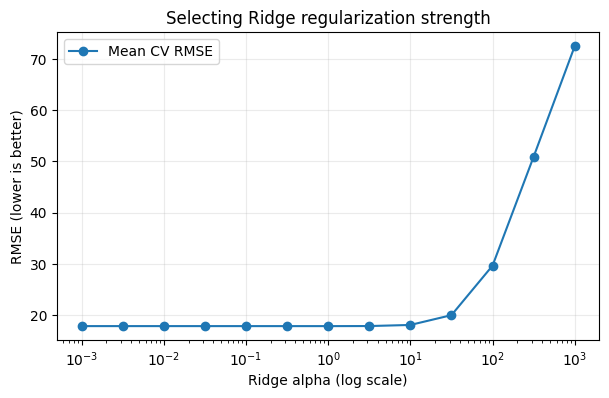

In [11]:
cv_results = pd.DataFrame(ridge_search.cv_results_)
plt.figure(figsize=(7, 4))
plt.semilogx(
    cv_results["param_model__alpha"].astype(float),
    np.sqrt(-cv_results["mean_test_score"]),
    marker="o",
    label="Mean CV RMSE"
)
plt.xlabel("Ridge alpha (log scale)")
plt.ylabel("RMSE (lower is better)")
plt.title("Selecting Ridge regularization strength")
plt.grid(alpha=0.25)
plt.legend()
plt.show()

The cross-validation curve illustrates the bias–variance trade-off. Very weak regularization may leave a model sensitive to noisy features; very strong regularization can shrink useful effects too much. Choose the value that performs well on validation folds, then report final performance on the separate test set.

## 7. Comparing regularized models with cross-validation

In [12]:
candidates = {
    "OLS": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Ridge": Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
    "Lasso": Pipeline([("scale", StandardScaler()), ("model", Lasso(max_iter=20000, random_state=RANDOM_STATE))]),
    "ElasticNet": Pipeline([("scale", StandardScaler()), ("model", ElasticNet(max_iter=20000, random_state=RANDOM_STATE))]),
}
grids = {
    "OLS": {},
    "Ridge": {"model__alpha": np.logspace(-3, 3, 10)},
    "Lasso": {"model__alpha": np.logspace(-3, 1, 10)},
    "ElasticNet": {
        "model__alpha": np.logspace(-3, 1, 8),
        "model__l1_ratio": [0.2, 0.5, 0.8, 0.95]
    }
}

cv_rows = []
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, estimator in candidates.items():
    if grids[name]:
        search = GridSearchCV(
            estimator, grids[name], scoring="neg_mean_squared_error",
            cv=cv, n_jobs=-1
        )
        search.fit(X_train, y_train)
        fitted = search.best_estimator_
        best_params = search.best_params_
        cv_rmse = np.sqrt(-search.best_score_)
    else:
        scores = cross_validate(
            estimator, X_train, y_train, scoring="neg_mean_squared_error",
            cv=cv, n_jobs=-1
        )
        cv_rmse = np.sqrt(-scores["test_score"].mean())
        fitted = estimator.fit(X_train, y_train)
        best_params = {}

    cv_rows.append({
        "Model": name,
        "Mean CV RMSE": cv_rmse,
        "Test RMSE": regression_metrics(fitted, X_test, y_test)["RMSE"],
        "Test R2": regression_metrics(fitted, X_test, y_test)["R2"],
        "Best parameters": str(best_params)
    })

cv_comparison = pd.DataFrame(cv_rows).set_index("Model").sort_values("Mean CV RMSE")
display(cv_comparison.round(3))

,Mean CV RMSE,Test RMSE,Test R2,Best parameters
Model,,,,
Lasso,17.776,18.069,0.969,{'model__alpha': np.float64(0.46415888336127775)}
ElasticNet,17.835,17.875,0.969,{'model__alpha': np.float64(0.0517947467923121...
Ridge,17.847,17.816,0.970,{'model__alpha': np.float64(0.46415888336127775)}
OLS,17.849,17.791,0.970,{}


**Evaluation guidance**
- MSE squares errors and penalizes large errors more heavily.
- RMSE is in the same units as the target, making it easier to interpret.
- MAE is the average absolute error and is less sensitive to extreme errors than MSE.
- \(R^2\) compares the model with a constant-mean baseline; it can be negative on test data if the model performs worse than that baseline.
- Compare models using the same data splits and metrics. Do not use test-set results to repeatedly tune hyperparameters.

## 8. A quick example of polynomial features

Linear models can model curved relationships when nonlinear features are created first. `PolynomialFeatures` expands the inputs, and a regularized model can help control the larger feature set. This is an extension of the chapter's regression/regularization ideas; it is not a claim that every relationship is polynomial.

Polynomial Ridge test metrics:


,MSE,RMSE,MAE,R2
Degree-2 Polynomial + Ridge,2.775,1.666,1.358,0.784


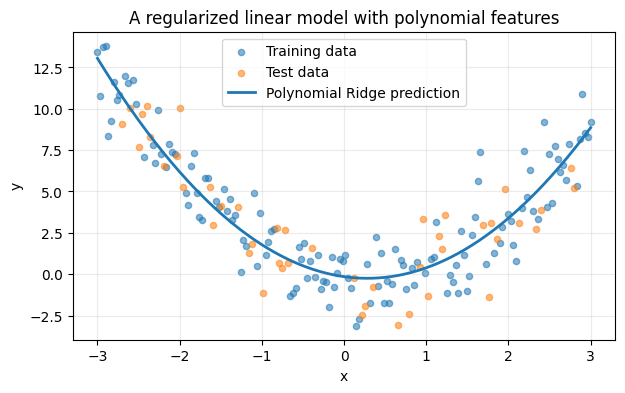

In [13]:
rng = np.random.default_rng(RANDOM_STATE)
X_curve = np.linspace(-3, 3, 180).reshape(-1, 1)
y_curve = 1.2 * X_curve[:, 0]**2 - 0.7 * X_curve[:, 0] + rng.normal(0, 1.8, len(X_curve))

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_curve, y_curve, test_size=0.25, random_state=RANDOM_STATE
)

poly_ridge = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scale", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])
poly_ridge.fit(Xc_train, yc_train)
print("Polynomial Ridge test metrics:")
display(pd.DataFrame([regression_metrics(poly_ridge, Xc_test, yc_test)], index=["Degree-2 Polynomial + Ridge"]).round(3))

x_plot = np.linspace(-3, 3, 300).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(Xc_train[:, 0], yc_train, s=20, alpha=0.55, label="Training data")
plt.scatter(Xc_test[:, 0], yc_test, s=20, alpha=0.55, label="Test data")
plt.plot(x_plot[:, 0], poly_ridge.predict(x_plot), linewidth=2, label="Polynomial Ridge prediction")
plt.xlabel("x")
plt.ylabel("y")
plt.title("A regularized linear model with polynomial features")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 9. Hands-on exercises

1. **Change noise:** regenerate the dataset with `noise=35`. Compare test RMSE and \(R^2\). Does the task become harder?
2. **Change Ridge alpha:** try `alpha=0.01`, `1`, `100`, and `1000`. Track test RMSE and coefficient magnitudes.
3. **Lasso sparsity:** vary `alpha` from `0.01` to `10`. Count coefficients close to zero and compare prediction performance.
4. **Elastic Net mix:** test `l1_ratio` values of `0.1`, `0.5`, and `0.9` with cross-validation.
5. **Avoid leakage:** fit a scaler on the full dataset before splitting, then compare with the pipeline approach. Explain why the pipeline is the sounder evaluation design, even if the numerical difference is small.

For each exercise, record the settings, metrics, and a short explanation of the observed trade-offs.

## 10. Chapter summary

- OLS provides a simple baseline by minimizing squared residuals.
- Ridge (L2) shrinks coefficients; Lasso (L1) can eliminate features by setting coefficients to zero.
- Elastic Net combines the two penalties and can be useful when sparsity and stability are both desired.
- Scaling is important for penalized models, and it should be fitted only on training data.
- Tune `alpha` (and Elastic Net's `l1_ratio`) using cross-validation.
- Use a held-out test set for the final, unbiased comparison and interpret metrics in context.

**Main takeaway:** regularization is a practical way to control model complexity, but the penalty strength must be selected empirically with a sound validation workflow.